# Landmark Recognition Using the SIFT Algorithm
**Lab Assignment: Computer Vision with Python + OpenCV**

A tourism information centre wants an automated system: a visitor uploads a photo, the system names the landmark, shows how sure it is, and draws a box around the landmark in the photo.

### Pipeline
| Stage | What happens | Task |
|---|---|---|
| 1 | Build an organised landmark image database (one folder per landmark) | Task 1 |
| 2 | Convert to grayscale, detect SIFT keypoints, extract 128-D descriptors, store them with labels | Task 2 |
| 3 | Load an unknown query image and extract its SIFT features | Task 3 |
| 4 | Brute-Force matcher (L2) + KNN (k=2) + Lowe's ratio test, count reliable matches, rank landmarks, apply thresholds | Task 4 |
| 5 | RANSAC homography, project reference corners, draw polygon, report inliers | Task 5 |
| 6 | Test with original / rotated / resized / dark / different-viewpoint / unknown images | Task 6 |

### Dataset
The notebook uses the Kaggle dataset **Wonders of the World Image Classification** (`balabaskar/wonders-of-the-world-image-classification`), downloaded automatically with `kagglehub`. You do **not** need to download anything manually. Run the cells top to bottom (**Runtime → Run all**).

> The class folders are discovered automatically, so the code still works if the dataset's internal folder layout differs from what I expected.

## 0. Setup

In [ ]:
!pip install -q kagglehub

import os, re, glob, shutil, time, random, zipfile
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
assert hasattr(cv2, "SIFT_create"), "SIFT not available - upgrade opencv-python (>= 4.4)"

plt.rcParams["figure.dpi"] = 110

OpenCV version: 4.14.0


### Configuration
All tunable parameters live in one place. The **thresholds** (`MIN_GOOD`, `MIN_INLIERS`, `MIN_INLIER_RATIO`) decide whether a match is accepted or the image is rejected as an unknown landmark. Task 6 includes a sensitivity sweep to help you choose them.

In [ ]:
# ---------- Reproducibility ----------
SEED = 42

# ---------- Database construction ----------
N_LANDMARKS = 6            # number of landmarks in the database (>= 5 required)
N_REF = 8                  # reference images per landmark (stored in the database)
N_QUERY = 3                # held-out query images per landmark (never in the database)
N_UNKNOWN_CLASSES = 2      # landmark classes completely excluded from the database
N_UNKNOWN_PER_CLASS = 3    # query images taken from each excluded class
MAX_SIDE = 800             # longest image side (px) after resizing, keeps SIFT fast

# Optional: force specific classes (exact folder names). Leave as None for automatic choice.
MANUAL_LANDMARKS = None    # e.g. ["taj_mahal", "Roman Colosseum", ...]

# ---------- SIFT / matching ----------
N_FEATURES = 2000          # cap on keypoints per image (0 = unlimited)
RATIO = 0.75               # Lowe's ratio test threshold
RANSAC_THRESH = 5.0        # reprojection error (px) for RANSAC inliers
TOP_K_VERIFY = 3           # top-ranked landmarks that receive geometric verification

# ---------- Decision thresholds (reject unknown / wrong matches) ----------
MIN_GOOD = 15              # minimum reliable (ratio-test) matches
MIN_INLIERS = 10           # minimum RANSAC inliers
MIN_INLIER_RATIO = 0.25    # inliers / reliable matches

# ---------- Folders ----------
WORK_DIR = "/content"
DB_DIR = f"{WORK_DIR}/landmark_db"
QUERY_DIR = f"{WORK_DIR}/landmark_queries"
FEAT_DIR = f"{WORK_DIR}/sift_features"
OUT_DIR = f"{WORK_DIR}/outputs"
for d in (DB_DIR, QUERY_DIR, FEAT_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

rng = random.Random(SEED)
np.random.seed(SEED)

## Download the dataset (kagglehub)
> If Colab reports an authentication / 403 error, add your Kaggle credentials via **Colab Secrets** (`KAGGLE_USERNAME`, `KAGGLE_KEY`) or run `kagglehub.login()` once, then re-run this cell.

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("balabaskar/wonders-of-the-world-image-classification")
print("Dataset downloaded to:", dataset_path)

100%|██████████| 432M/432M [00:04<00:00, 107MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2


### Explore the dataset
Every folder that directly contains images is treated as one landmark class. If the dataset is split into `train/test/val`, the same class from different splits is merged.

In [ ]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_files = defaultdict(list)
for root, dirs, files in os.walk(dataset_path):
    imgs = [os.path.join(root, f) for f in files if f.lower().endswith(IMG_EXT)]
    if imgs:
        class_files[os.path.basename(root)].extend(imgs)

class_files = {k: sorted(set(v)) for k, v in class_files.items()}

summary = pd.DataFrame({"class_folder": list(class_files.keys()),
                        "num_images": [len(v) for v in class_files.values()]}).sort_values("class_folder")
display(summary.reset_index(drop=True))
print(f"Found {len(class_files)} classes, {summary.num_images.sum()} images in total.")

if len(class_files) < N_LANDMARKS + 1:
    print("\nDataset folder tree (top levels) for debugging:")
    for root, dirs, files in os.walk(dataset_path):
        if root.count(os.sep) - dataset_path.count(os.sep) <= 2:
            print(root, "->", len(files), "files")

,class_folder,num_images
0,burj_khalifa,390
1,chichen_itza,340
2,christ_the_reedemer,323
3,eiffel_tower,391
4,great_wall_of_china,392
5,machu_pichu,393
6,pyramids_of_giza,372
7,roman_colosseum,394
8,statue_of_liberty,238
9,stonehenge,204


Found 12 classes, 3846 images in total.


## Task 1: Landmark Image Database

From the dataset we:
1. Select **N_LANDMARKS** landmark classes (preferring famous ones such as the Taj Mahal, Colosseum, Great Wall, Statue of Liberty, Pyramids).
2. Copy **N_REF** images per landmark into `landmark_db/<landmark>/`. These show different viewing angles and distances.
3. Set aside **N_QUERY** *different* images per landmark as test queries, so a query is never identical to a reference image.
4. Keep one or more classes **entirely out of the database** to serve as "unknown landmark" tests.

Images are resized to a maximum side of `MAX_SIDE` px for speed.

In [ ]:
def norm(s):
    return re.sub(r"[^a-z0-9]+", " ", s.lower()).strip()

def slug(s):
    return norm(s).replace(" ", "_")

def pretty(s):
    return norm(s).title()

def resize_max(img, max_side=MAX_SIDE):
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

def load_valid_images(paths, n):
    # Return the first n readable images (path, bgr) from a list of paths.
    out = []
    for p in paths:
        img = cv2.imread(p)
        if img is None or min(img.shape[:2]) < 100:
            continue
        out.append((p, resize_max(img)))
        if len(out) == n:
            break
    return out

# ---- choose landmark classes ----
need = N_REF + N_QUERY
eligible = [c for c, v in class_files.items() if len(v) >= need]

if MANUAL_LANDMARKS:
    chosen = [c for c in MANUAL_LANDMARKS if c in class_files]
else:
    PREFERRED = ["taj", "colosseum", "great wall", "liberty", "eiffel", "pyramid", "christ", "machu", "petra"]
    chosen = []
    for kw in PREFERRED:
        for c in eligible:
            if kw in norm(c) and c not in chosen:
                chosen.append(c)
                break
        if len(chosen) == N_LANDMARKS:
            break
    for c in eligible:                         # fill up if not enough preferred classes were found
        if len(chosen) >= N_LANDMARKS:
            break
        if c not in chosen:
            chosen.append(c)

# ---- choose 'unknown' classes (never enter the database) ----
remaining = [c for c in class_files if c not in chosen and len(class_files[c]) >= N_UNKNOWN_PER_CLASS]
UNK_PREF = ["stonehenge", "petra", "chichen", "machu", "christ"]
unknown_classes = []
for kw in UNK_PREF:
    for c in remaining:
        if kw in norm(c) and c not in unknown_classes:
            unknown_classes.append(c)
            break
for c in remaining:
    if len(unknown_classes) >= N_UNKNOWN_CLASSES:
        break
    if c not in unknown_classes:
        unknown_classes.append(c)
unknown_classes = unknown_classes[:N_UNKNOWN_CLASSES]

assert len(chosen) >= 5, "Need at least 5 landmark classes with enough images."
print("Database landmarks :", [pretty(c) for c in chosen])
print("Unknown (held out) :", [pretty(c) for c in unknown_classes])

# ---- build folders ----
for d in (DB_DIR, QUERY_DIR):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)

for c in chosen:
    paths = class_files[c][:]
    rng.shuffle(paths)
    imgs = load_valid_images(paths, need + 5)          # a few spare in case of unreadable files
    ref, qry = imgs[:N_REF], imgs[N_REF:N_REF + N_QUERY]
    os.makedirs(f"{DB_DIR}/{slug(c)}", exist_ok=True)
    os.makedirs(f"{QUERY_DIR}/{slug(c)}", exist_ok=True)
    for i, (_, im) in enumerate(ref, 1):
        cv2.imwrite(f"{DB_DIR}/{slug(c)}/{slug(c)}_{i:02d}.jpg", im)
    for i, (_, im) in enumerate(qry, 1):
        cv2.imwrite(f"{QUERY_DIR}/{slug(c)}/query_{i:02d}.jpg", im)

os.makedirs(f"{QUERY_DIR}/_unknown", exist_ok=True)
for c in unknown_classes:
    paths = class_files[c][:]
    rng.shuffle(paths)
    for i, (_, im) in enumerate(load_valid_images(paths, N_UNKNOWN_PER_CLASS), 1):
        cv2.imwrite(f"{QUERY_DIR}/_unknown/{slug(c)}_{i:02d}.jpg", im)

print("\nDatabase structure:")
for d in sorted(os.listdir(DB_DIR)):
    print(f"  {d}/  ->  {len(os.listdir(f'{DB_DIR}/{d}'))} reference images")

Database landmarks : ['Taj Mahal', 'Roman Colosseum', 'Great Wall Of China', 'Statue Of Liberty', 'Eiffel Tower', 'Pyramids Of Giza']
Unknown (held out) : ['Stonehenge', 'Chichen Itza']

Database structure:
  eiffel_tower/  ->  8 reference images
  great_wall_of_china/  ->  8 reference images
  pyramids_of_giza/  ->  8 reference images
  roman_colosseum/  ->  8 reference images
  statue_of_liberty/  ->  8 reference images
  taj_mahal/  ->  8 reference images


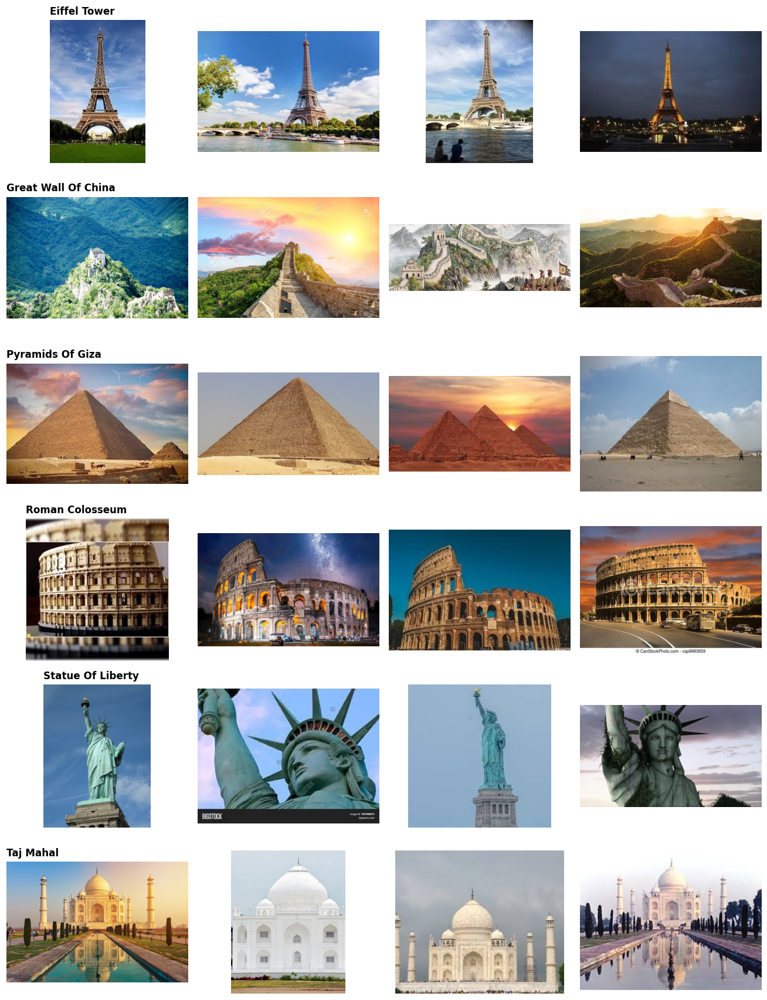

In [ ]:
# Preview the database: 4 reference images per landmark
lm_dirs = sorted(os.listdir(DB_DIR))
fig, axes = plt.subplots(len(lm_dirs), 4, figsize=(12, 2.6 * len(lm_dirs)))
for r, d in enumerate(lm_dirs):
    files = sorted(glob.glob(f"{DB_DIR}/{d}/*.jpg"))[:4]
    for c in range(4):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(files):
            ax.imshow(cv2.cvtColor(cv2.imread(files[c]), cv2.COLOR_BGR2RGB))
            if c == 0:
                ax.set_title(pretty(d), loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/task1_database_preview.png", bbox_inches="tight")
plt.show()

## Task 2: SIFT Feature Extraction

For every reference image we
1. load it and convert it to **grayscale**,
2. detect **keypoints** with SIFT (scale-space extrema in a Difference-of-Gaussians pyramid, contrast + edge filtering),
3. compute the **128-D descriptor** (4×4 spatial cells × 8 orientation bins, normalised and clipped at 0.2),
4. display the keypoints, and
5. store the descriptors together with the landmark label.

In [ ]:
sift = cv2.SIFT_create(nfeatures=N_FEATURES)

def extract_sift(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    return kp, des, gray

# database[label] = list of dicts {path, img, kp, des}
database = {}
t0 = time.perf_counter()
for d in sorted(os.listdir(DB_DIR)):
    label = pretty(d)
    database[label] = []
    for p in sorted(glob.glob(f"{DB_DIR}/{d}/*.jpg")):
        img = cv2.imread(p)
        kp, des, gray = extract_sift(img)
        if des is None or len(kp) < 2:
            print("skipped (no features):", p)
            continue
        database[label].append({"path": p, "img": img, "kp": kp, "des": des})

print(f"Feature extraction finished in {time.perf_counter() - t0:.1f}s\n")
stats = pd.DataFrame([{"Landmark": k, "Ref images": len(v),
                       "Avg keypoints / image": int(np.mean([len(r['kp']) for r in v])),
                       "Descriptor shape": v[0]['des'].shape[1:]} for k, v in database.items()])
display(stats)

# Store descriptors + labels on disk (npz per landmark)
for label, refs in database.items():
    np.savez_compressed(
        f"{FEAT_DIR}/{slug(label)}.npz",
        label=label,
        paths=np.array([r["path"] for r in refs]),
        **{f"des_{i}": r["des"] for i, r in enumerate(refs)},
        **{f"kp_xy_{i}": np.array([k.pt for k in r["kp"]], dtype=np.float32) for i, r in enumerate(refs)},
    )
print("\nDescriptors saved to", FEAT_DIR, "->", sorted(os.listdir(FEAT_DIR)))

Feature extraction finished in 3.0s



,Landmark,Ref images,Avg keypoints / image,Descriptor shape
0,Eiffel Tower,8,924,"(128,)"
1,Great Wall Of China,8,1092,"(128,)"
2,Pyramids Of Giza,8,657,"(128,)"
3,Roman Colosseum,8,941,"(128,)"
4,Statue Of Liberty,8,412,"(128,)"
5,Taj Mahal,8,992,"(128,)"



Descriptors saved to /content/sift_features -> ['eiffel_tower.npz', 'great_wall_of_china.npz', 'pyramids_of_giza.npz', 'roman_colosseum.npz', 'statue_of_liberty.npz', 'taj_mahal.npz']


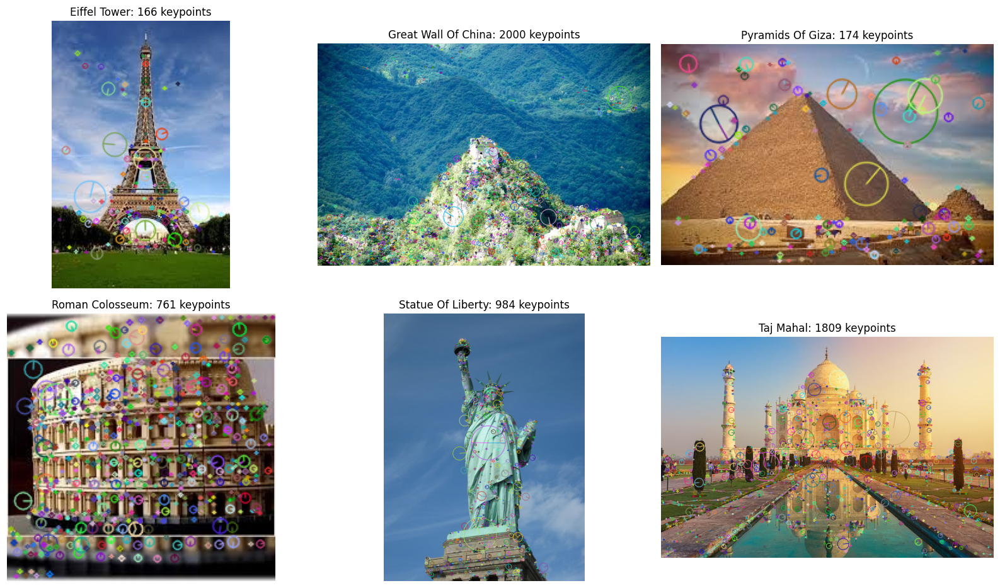

In [ ]:
# Display reference images with their detected keypoints (one per landmark)
labels = list(database.keys())
cols = 3
rows = int(np.ceil(len(labels) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 4.3 * rows))
axes = np.array(axes).reshape(-1)
for ax in axes:
    ax.axis("off")
for ax, label in zip(axes, labels):
    r = database[label][0]
    vis = cv2.drawKeypoints(r["img"], r["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{label}: {len(r['kp'])} keypoints", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/task2_reference_keypoints.png", bbox_inches="tight")
plt.show()

## Task 3: Query Image Processing
A query image is loaded, converted to grayscale, and its SIFT keypoints and descriptors are extracted and displayed. Here we use a *held-out* image of the first landmark.

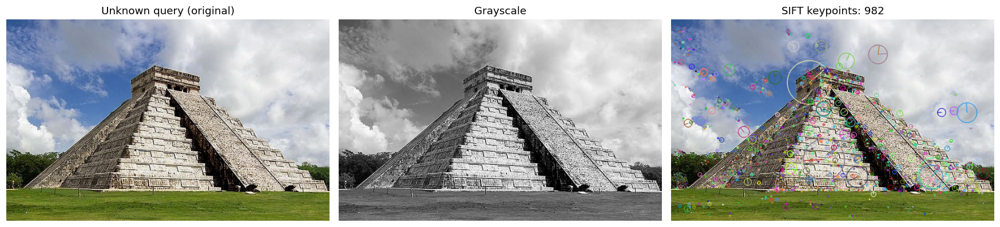

Keypoints: 982 | Descriptor matrix: (982, 128)


In [ ]:
def process_query(img_bgr, title="Query", save_path=None):
    kp, des, gray = extract_sift(img_bgr)
    vis = cv2.drawKeypoints(img_bgr, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    ax[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"{title} (original)")
    ax[1].imshow(gray, cmap="gray");                       ax[1].set_title("Grayscale")
    ax[2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB));    ax[2].set_title(f"SIFT keypoints: {len(kp)}")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()
    print(f"Keypoints: {len(kp)} | Descriptor matrix: {None if des is None else des.shape}")
    return kp, des

demo_dir = sorted(os.listdir(QUERY_DIR))[0]
demo_path = sorted(glob.glob(f"{QUERY_DIR}/{demo_dir}/*.jpg"))[0]
demo_img = cv2.imread(demo_path)
_ = process_query(demo_img, title=pretty(demo_dir) + " query", save_path=f"{OUT_DIR}/task3_query_keypoints.png")

## Task 4: Feature Matching and Landmark Recognition

For each landmark we compare the query descriptors against every reference image of that landmark:

1. **Brute-Force matcher** with the **Euclidean (L2)** distance, which is the right metric for SIFT's float descriptors.
2. **KNN matching with k = 2**: the two nearest reference descriptors for each query descriptor.
3. **Lowe's ratio test**: keep a match only if `d1 < RATIO × d2`. This removes ambiguous matches whose best and second-best candidates are almost equally close.
4. Count the reliable matches. A landmark's score is its **best reference image** (taking the max rather than the sum avoids favouring landmarks that merely have more reference images).
5. **Rank** the landmarks by score.

> **Why the largest match count alone is not enough.** Every query gets *some* top-ranked landmark, even an unrelated one. So the final decision (Task 5) also needs a minimum match count, **geometric verification (RANSAC inliers)**, and a minimum inlier ratio. Otherwise an unknown landmark would always be mislabelled.

In [ ]:
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

def ratio_test_matches(des_q, des_r, ratio=RATIO):
    # KNN (k=2) + Lowe's ratio test. queryIdx -> des_q, trainIdx -> des_r.
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    knn = bf.knnMatch(des_q, des_r, k=2)
    good = []
    for pair in knn:
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance:
            good.append(pair[0])
    return good

def rank_landmarks(des_q):
    # Stage 1: for every landmark find its best reference image (max reliable matches).
    per_landmark = []
    for label, refs in database.items():
        best = {"label": label, "ref_idx": -1, "good": [], "n_good": -1}
        for i, r in enumerate(refs):
            good = ratio_test_matches(des_q, r["des"])
            if len(good) > best["n_good"]:
                best = {"label": label, "ref_idx": i, "good": good, "n_good": len(good)}
        per_landmark.append(best)
    return sorted(per_landmark, key=lambda d: -d["n_good"])

# ---- demo on the query from Task 3 ----
kp_q, des_q, _ = extract_sift(demo_img)
ranking = rank_landmarks(des_q)
display(pd.DataFrame([{"Rank": i + 1, "Landmark": r["label"], "Best ref image": r["ref_idx"] + 1,
                       "Reliable matches": r["n_good"]} for i, r in enumerate(ranking)]))

,Rank,Landmark,Best ref image,Reliable matches
0,1,Pyramids Of Giza,1,19
1,2,Statue Of Liberty,8,16
2,3,Eiffel Tower,1,12
3,4,Great Wall Of China,3,11
4,5,Taj Mahal,7,11
5,6,Roman Colosseum,6,9


## Task 5: Landmark Localization and Final Decision

For the top-ranked candidates (`TOP_K_VERIFY`) we:
1. collect the corresponding keypoint coordinates (reference to query),
2. estimate a **homography with RANSAC**,
3. project the **four corners of the reference image** into the query image,
4. check that the projected quadrilateral is a plausible shape (convex, sensible area) and
5. count the **RANSAC inliers**.

The final label is the candidate with the most **inliers**, which is more trustworthy than raw match counts because inliers must agree on one geometric transformation. The image is **recognized** only if it passes all three thresholds (`MIN_GOOD`, `MIN_INLIERS`, `MIN_INLIER_RATIO`) and the polygon is valid; otherwise it is **rejected**, and no polygon is drawn.

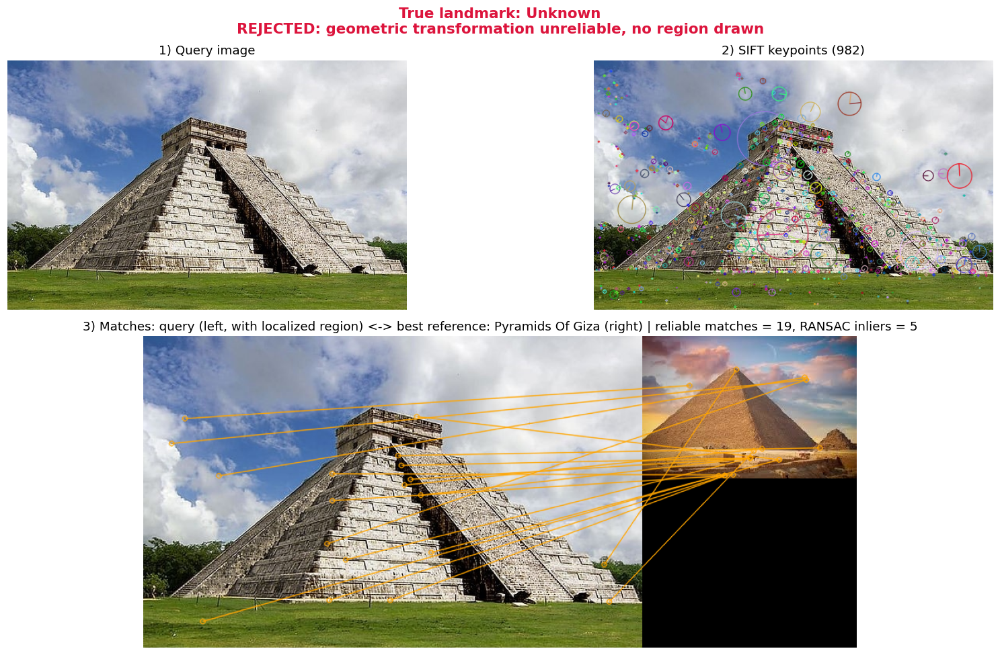

Predicted: Pyramids Of Giza | reliable matches: 19 | RANSAC inliers: 5 | time: 1.13s


In [ ]:
def geometric_verify(kp_q, kp_r, good, ref_shape, query_shape):
    # Homography (reference -> query) with RANSAC. Returns dict or None.
    if len(good) < 4:
        return None
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None or mask is None:
        return None
    inliers = int(mask.sum())
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H)
    q_area = query_shape[0] * query_shape[1]
    finite = bool(np.isfinite(poly).all())
    convex = finite and cv2.isContourConvex(poly.astype(np.float32))
    area = cv2.contourArea(poly.astype(np.float32)) if finite else 0.0
    valid = bool(convex and 0.01 * q_area < area < 4 * q_area)
    return {"H": H, "mask": mask.ravel().astype(bool), "inliers": inliers, "poly": poly, "valid": valid}

def decide(n_good, inliers, valid, min_good=None, min_inliers=None, min_ratio=None):
    min_good = MIN_GOOD if min_good is None else min_good
    min_inliers = MIN_INLIERS if min_inliers is None else min_inliers
    min_ratio = MIN_INLIER_RATIO if min_ratio is None else min_ratio
    ratio = inliers / n_good if n_good else 0.0
    return bool(valid and n_good >= min_good and inliers >= min_inliers and ratio >= min_ratio)

def recognize(query_bgr):
    # Full pipeline: SIFT -> BF+KNN+ratio -> rank -> RANSAC -> decision.
    t0 = time.perf_counter()
    kp_q, des_q, _ = extract_sift(query_bgr)
    res = {"kp_q": kp_q, "n_kp": len(kp_q), "ranking": [], "best": None, "geo": None,
           "recognized": False, "pred": "-", "n_good": 0, "inliers": 0, "valid": False}
    if des_q is None or len(kp_q) < 2:
        res["message"] = "REJECTED: not enough features in the query image"
        res["time_s"] = time.perf_counter() - t0
        return res

    ranking = rank_landmarks(des_q)                       # Stage 1: matching + ranking
    for cand in ranking[:TOP_K_VERIFY]:                   # Stage 2: geometric verification
        ref = database[cand["label"]][cand["ref_idx"]]
        cand["geo"] = geometric_verify(kp_q, ref["kp"], cand["good"], ref["img"].shape, query_bgr.shape)
        cand["inliers"] = cand["geo"]["inliers"] if cand["geo"] else 0
    for cand in ranking[TOP_K_VERIFY:]:
        cand["geo"], cand["inliers"] = None, 0

    best = max(ranking[:TOP_K_VERIFY], key=lambda d: (d["inliers"], d["n_good"]))
    geo = best["geo"]
    valid = bool(geo and geo["valid"])
    recognized = decide(best["n_good"], best["inliers"], valid)

    if recognized:
        msg = f"RECOGNIZED: {best['label']}"
    elif best["n_good"] < MIN_GOOD:
        msg = "REJECTED: too few reliable matches (unknown landmark?)"
    elif not valid:
        msg = "REJECTED: geometric transformation unreliable, no region drawn"
    elif best["inliers"] < MIN_INLIERS:
        msg = "REJECTED: too few RANSAC inliers"
    else:
        msg = "REJECTED: inlier ratio too low"

    res.update({"ranking": ranking, "best": best, "geo": geo, "recognized": recognized,
                "pred": best["label"], "n_good": best["n_good"], "inliers": best["inliers"],
                "valid": valid, "message": msg, "time_s": time.perf_counter() - t0})
    return res

def show_result(res, query_bgr, title=None, save_path=None):
    kp_q = res["kp_q"]
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25])
    ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])

    ax1.imshow(cv2.cvtColor(query_bgr, cv2.COLOR_BGR2RGB)); ax1.set_title("1) Query image")
    vis = cv2.drawKeypoints(query_bgr, kp_q, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax2.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB));       ax2.set_title(f"2) SIFT keypoints ({res['n_kp']})")

    best, geo = res["best"], res["geo"]
    if best is not None:
        ref = database[best["label"]][best["ref_idx"]]
        q_vis = query_bgr.copy()
        if res["recognized"]:                                       # draw localisation polygon
            thick = max(3, int(0.006 * max(q_vis.shape[:2])))
            cv2.polylines(q_vis, [np.int32(geo["poly"])], True, (0, 0, 255), thick, cv2.LINE_AA)
            matches = [m for m, keep in zip(best["good"], geo["mask"]) if keep]
            color = (0, 255, 0)
        else:
            matches = best["good"][:60]
            color = (0, 165, 255)
        # matches: queryIdx -> query keypoints, trainIdx -> reference keypoints, so the query goes first
        canvas = cv2.drawMatches(q_vis, kp_q, ref["img"], ref["kp"], matches, None,
                                 matchColor=color, singlePointColor=(255, 0, 0),
                                 flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        ax3.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        ax3.set_title(f"3) Matches: query (left, with localized region) <-> best reference: {best['label']} (right) | "
                      f"reliable matches = {res['n_good']}, "
                      f"RANSAC inliers = {res['inliers']}")
    ax3.axis("off"); ax1.axis("off"); ax2.axis("off")
    color = "green" if res["recognized"] else "crimson"
    head = (title + "\n" if title else "") + res["message"]
    fig.suptitle(head, fontsize=14, fontweight="bold", color=color)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

# ---- demo: the query image from Task 3 ----
res = recognize(demo_img)
show_result(res, demo_img, title=f"True landmark: {pretty(demo_dir)}", save_path=f"{OUT_DIR}/task5_demo_result.png")
print(f"Predicted: {res['pred']} | reliable matches: {res['n_good']} | RANSAC inliers: {res['inliers']} | "
      f"time: {res['time_s']:.2f}s")

## Task 6: Performance Evaluation

### 6.1 Six test conditions (as required)
Starting from held-out images of one landmark we create:

| Condition | How |
|---|---|
| Original | a held-out query image (not in the database) |
| Rotated | the original rotated by 45° (canvas expanded, nothing cropped) |
| Resized | the original scaled to 50% |
| Reduced brightness | pixel values × 0.4 |
| Different viewpoint | a *different* held-out photo of the same landmark |
| Not in database | an image of an excluded landmark class |

In [ ]:
def rotate_image(img, angle):
    h, w = img.shape[:2]
    c = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(c, angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - c[0]
    M[1, 2] += nh / 2 - c[1]
    return cv2.warpAffine(img, M, (nw, nh), borderValue=(0, 0, 0))

def resize_scale(img, s):
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

def darken(img, alpha=0.4):
    return cv2.convertScaleAbs(img, alpha=alpha, beta=0)

# ---- pick the landmark used for the 6-condition test (change the index to test another) ----
TEST_IDX = 0
test_dir = sorted(os.listdir(QUERY_DIR))
test_dir = [d for d in test_dir if d != "_unknown"][TEST_IDX]
test_label = pretty(test_dir)
q_files = sorted(glob.glob(f"{QUERY_DIR}/{test_dir}/*.jpg"))
base = cv2.imread(q_files[0])
other_view = cv2.imread(q_files[1] if len(q_files) > 1 else q_files[0])
unk_files = sorted(glob.glob(f"{QUERY_DIR}/_unknown/*.jpg"))
unk_img = cv2.imread(unk_files[0])

tests = [
    ("Original",            base,                  test_label),
    ("Rotated (45 deg)",    rotate_image(base, 45), test_label),
    ("Resized (50%)",       resize_scale(base, .5), test_label),
    ("Reduced brightness",  darken(base, 0.4),     test_label),
    ("Different viewpoint", other_view,            test_label),
    ("Not in database",     unk_img,               "(not in database)"),
]

rows, results_6 = [], []
for name, img, truth in tests:
    r = recognize(img)
    results_6.append((name, img, truth, r))
    if truth == "(not in database)":
        correct = not r["recognized"]
    else:
        correct = r["recognized"] and r["pred"] == truth
    rows.append({"Test condition": name, "True landmark": truth,
                 "Predicted landmark": r["pred"] if r["recognized"] else f"{r['pred']} (rejected)",
                 "Keypoints (query)": r["n_kp"], "Reliable matches": r["n_good"],
                 "RANSAC inliers": r["inliers"],
                 "Decision": "Recognized" if r["recognized"] else "Rejected",
                 "Time (s)": round(r["time_s"], 2), "Correct": "yes" if correct else "NO"})

table6 = pd.DataFrame(rows)
display(table6)
table6.to_csv(f"{OUT_DIR}/task6_six_conditions.csv", index=False)

,Test condition,True landmark,Predicted landmark,Keypoints (query),Reliable matches,RANSAC inliers,Decision,Time (s),Correct
0,Original,Eiffel Tower,Eiffel Tower,270,23,17,Recognized,0.30,yes
1,Rotated (45 deg),Eiffel Tower,Eiffel Tower,372,22,18,Recognized,0.43,yes
2,Resized (50%),Eiffel Tower,Statue Of Liberty (rejected),69,2,0,Rejected,0.08,NO
3,Reduced brightness,Eiffel Tower,Eiffel Tower,127,15,14,Recognized,0.14,yes
4,Different viewpoint,Eiffel Tower,Eiffel Tower (rejected),296,6,0,Rejected,0.32,NO
5,Not in database,(not in database),Pyramids Of Giza (rejected),982,19,5,Rejected,1.08,yes


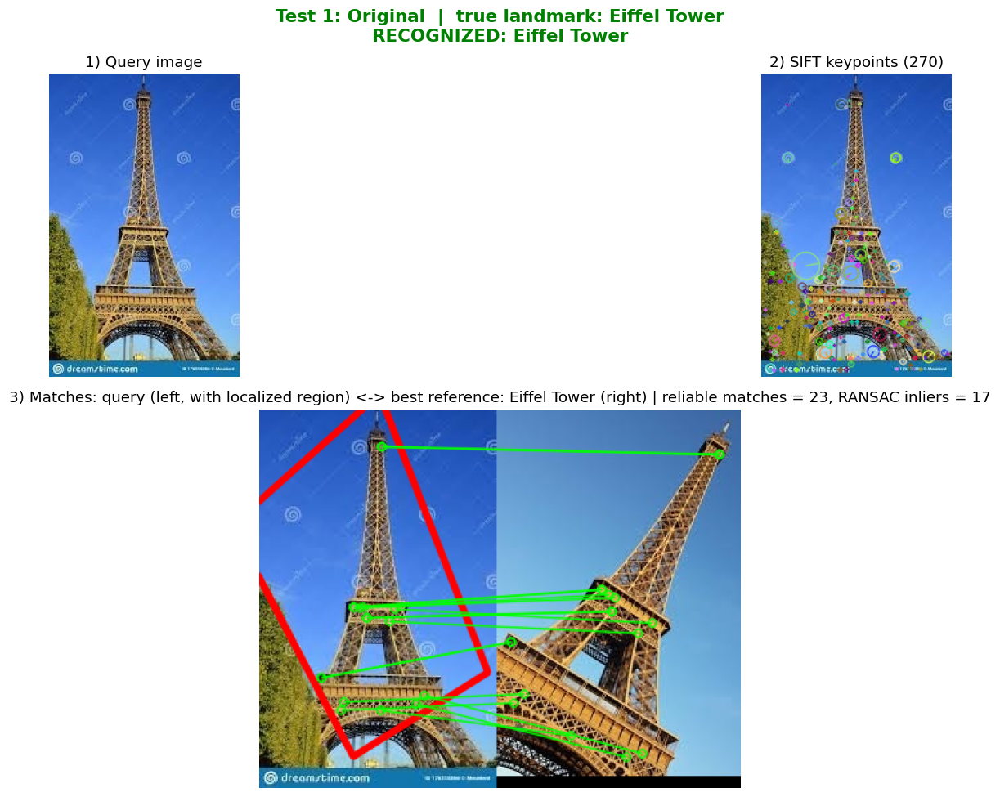

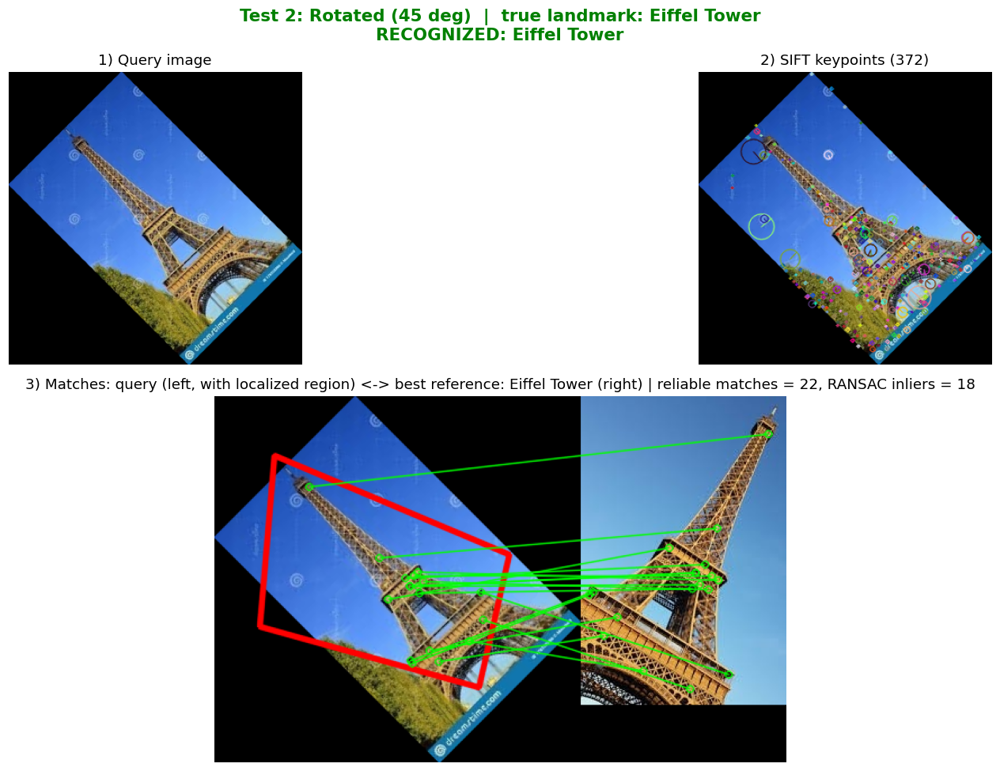

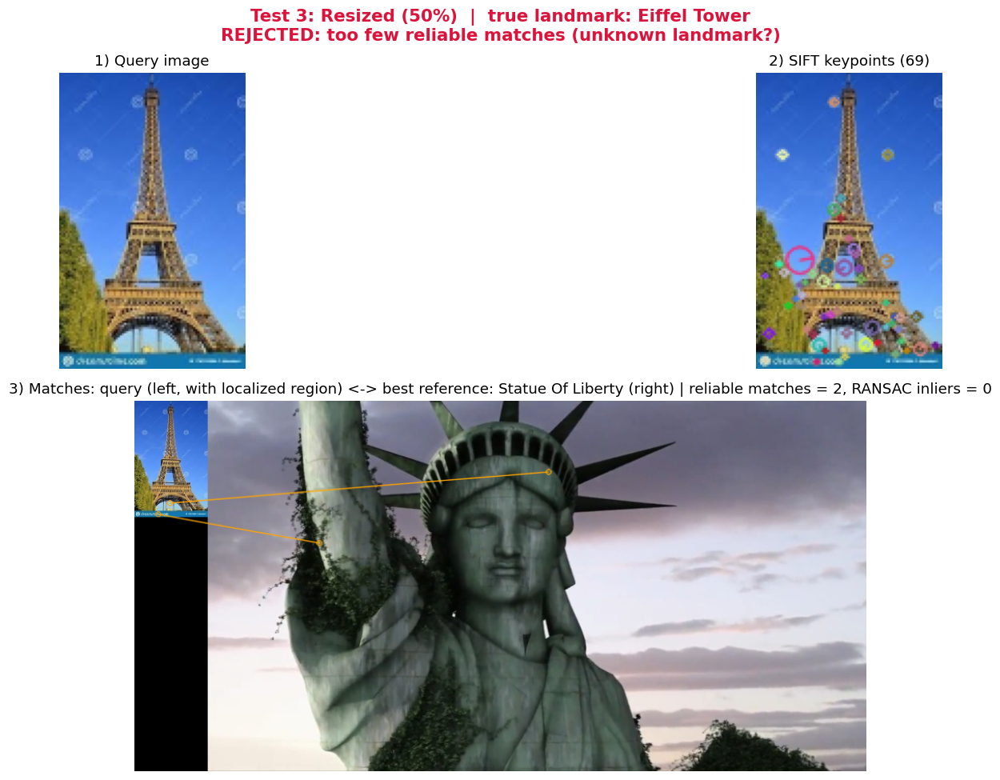

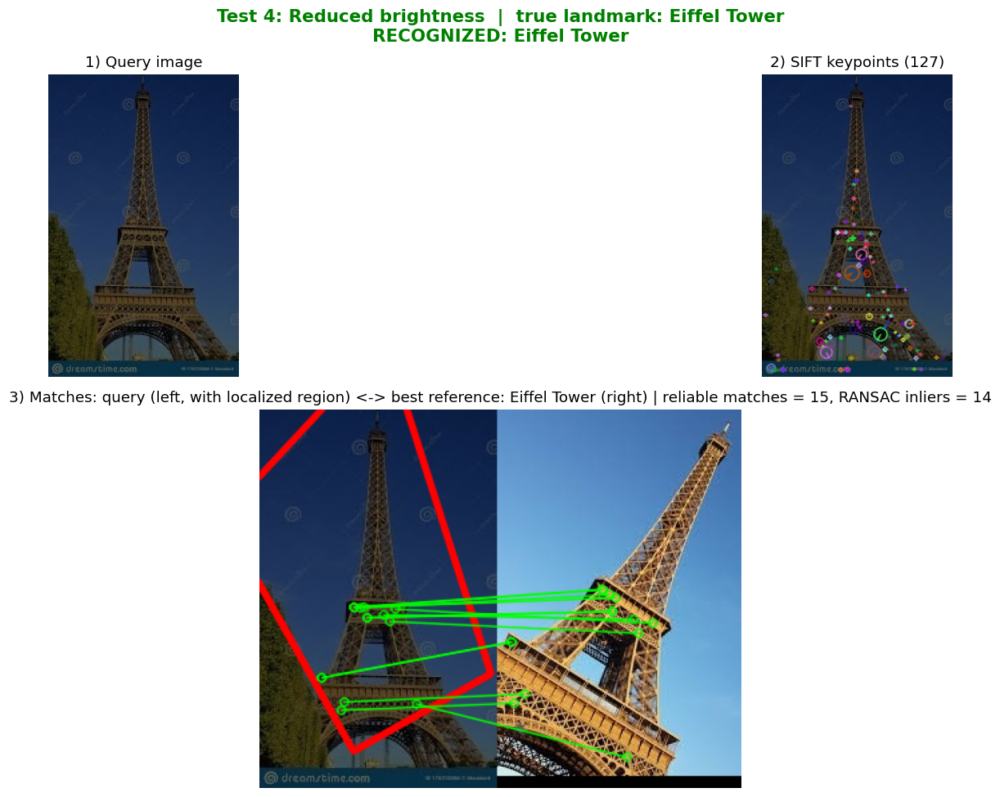

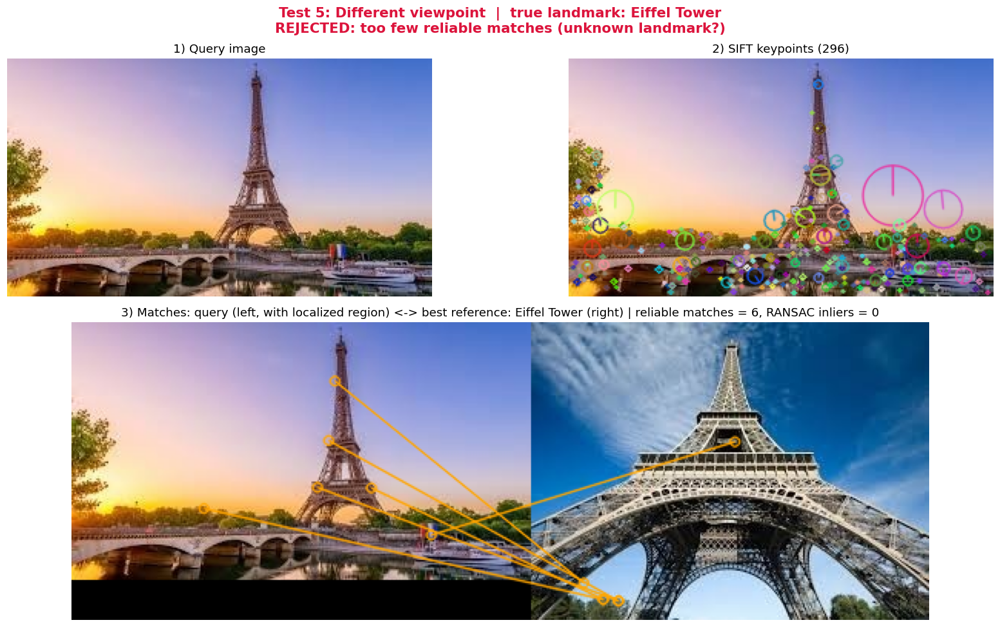

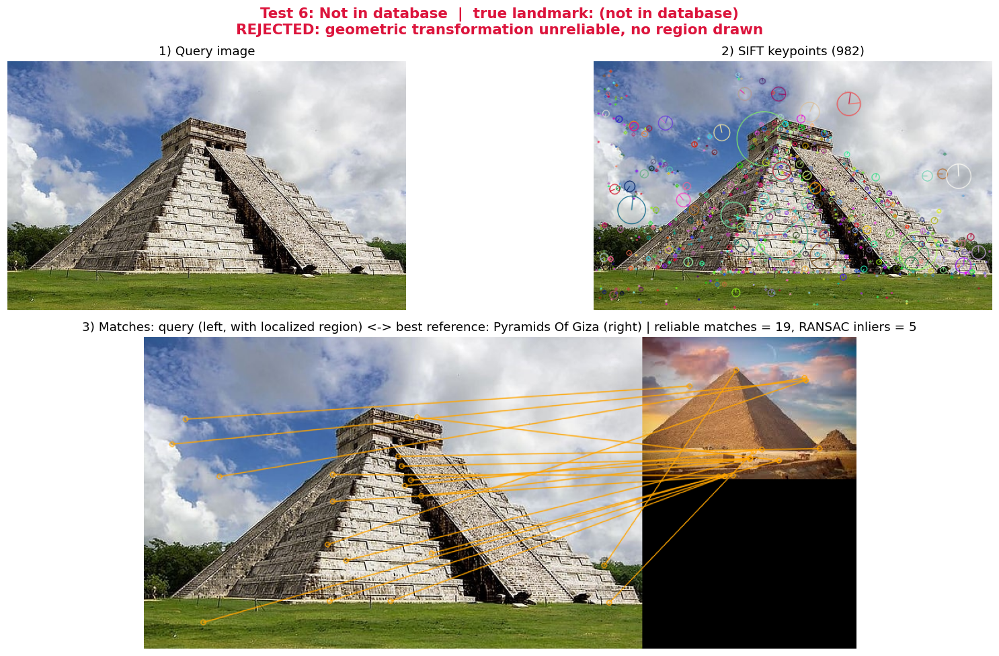

In [ ]:
# Screenshots of the application output for each test condition
for i, (name, img, truth, r) in enumerate(results_6, 1):
    show_result(r, img, title=f"Test {i}: {name}  |  true landmark: {truth}",
                save_path=f"{OUT_DIR}/task6_test{i}_{slug(name)}.png")

### 6.2 Evaluation over *all* held-out queries
Six images are a demonstration, not an evaluation. Here we run every held-out query for every landmark, plus the unknown-class images, and compute accuracy and a confusion matrix.

In [ ]:
eval_rows = []
for d in sorted(os.listdir(QUERY_DIR)):
    folder = f"{QUERY_DIR}/{d}"
    if d == "_unknown":
        items = [(p, "UNKNOWN") for p in sorted(glob.glob(f"{folder}/*.jpg"))]
    else:
        items = [(p, pretty(d)) for p in sorted(glob.glob(f"{folder}/*.jpg"))]
    for p, truth in items:
        img = cv2.imread(p)
        r = recognize(img)
        eval_rows.append({"file": os.path.basename(p), "true": truth, "top_candidate": r["pred"],
                          "n_kp": r["n_kp"], "n_good": r["n_good"], "inliers": r["inliers"],
                          "valid": r["valid"], "recognized": r["recognized"], "time_s": r["time_s"]})

ev = pd.DataFrame(eval_rows)
ev["final_pred"] = np.where(ev.recognized, ev.top_candidate, "UNKNOWN")
ev["correct"] = ev.final_pred == ev.true

known = ev[ev.true != "UNKNOWN"]
unk = ev[ev.true == "UNKNOWN"]
print(f"Known-landmark queries : {len(known)}")
print(f"  correctly recognized : {known.correct.sum()}  ({100 * known.correct.mean():.1f}%)")
print(f"  wrongly labelled     : {((known.final_pred != known.true) & (known.final_pred != 'UNKNOWN')).sum()}")
print(f"  falsely rejected     : {(known.final_pred == 'UNKNOWN').sum()}")
print(f"Unknown-landmark queries: {len(unk)}")
print(f"  correctly rejected   : {unk.correct.sum()}  ({100 * unk.correct.mean() if len(unk) else 0:.1f}%)")
print(f"Overall accuracy        : {100 * ev.correct.mean():.1f}%")
print(f"Mean processing time    : {ev.time_s.mean():.2f}s per query")

display(ev.drop(columns=["recognized"]).round(2))
display(pd.crosstab(ev.true, ev.final_pred, rownames=["True"], colnames=["Predicted"]))
ev.to_csv(f"{OUT_DIR}/task6_full_evaluation.csv", index=False)

Known-landmark queries : 18
  correctly recognized : 4  (22.2%)
  wrongly labelled     : 0
  falsely rejected     : 14
Unknown-landmark queries: 6
  correctly rejected   : 6  (100.0%)
Overall accuracy        : 41.7%
Mean processing time    : 0.95s per query


,file,true,top_candidate,n_kp,n_good,inliers,valid,time_s,final_pred,correct
0,chichen_itza_01.jpg,UNKNOWN,Pyramids Of Giza,982,19,5,False,1.14,UNKNOWN,True
1,chichen_itza_02.jpg,UNKNOWN,Statue Of Liberty,499,9,4,False,0.88,UNKNOWN,True
2,chichen_itza_03.jpg,UNKNOWN,Great Wall Of China,329,10,5,False,0.80,UNKNOWN,True
3,stonehenge_01.jpg,UNKNOWN,Great Wall Of China,1343,71,8,False,3.53,UNKNOWN,True
4,stonehenge_02.jpg,UNKNOWN,Pyramids Of Giza,166,4,4,False,0.18,UNKNOWN,True
5,stonehenge_03.jpg,UNKNOWN,Roman Colosseum,318,10,5,False,0.35,UNKNOWN,True
6,query_01.jpg,Eiffel Tower,Eiffel Tower,270,23,17,True,0.28,Eiffel Tower,True
7,query_02.jpg,Eiffel Tower,Eiffel Tower,296,6,0,False,0.33,UNKNOWN,False
8,query_03.jpg,Eiffel Tower,Eiffel Tower,746,11,9,True,0.77,UNKNOWN,False
9,query_01.jpg,Great Wall Of China,Taj Mahal,630,10,5,False,0.67,UNKNOWN,False


Predicted,Eiffel Tower,Great Wall Of China,Roman Colosseum,Taj Mahal,UNKNOWN
True,,,,,
Eiffel Tower,1,0,0,0,2
Great Wall Of China,0,1,0,0,2
Pyramids Of Giza,0,0,0,0,3
Roman Colosseum,0,0,1,0,2
Statue Of Liberty,0,0,0,0,3
Taj Mahal,0,0,0,1,2
UNKNOWN,0,0,0,0,6


### 6.3 Threshold sensitivity
The thresholds trade off *missed landmarks* against *false acceptances of unknown images*. We re-apply the decision rule to the stored measurements (no re-matching needed) for several `MIN_INLIERS` values.

,MIN_INLIERS,Known recognized (%),Unknown rejected (%)
0,4,27.8,100.0
1,6,27.8,100.0
2,8,22.2,100.0
3,10,22.2,100.0
4,12,22.2,100.0
5,15,22.2,100.0
6,20,11.1,100.0
7,25,11.1,100.0
8,30,11.1,100.0


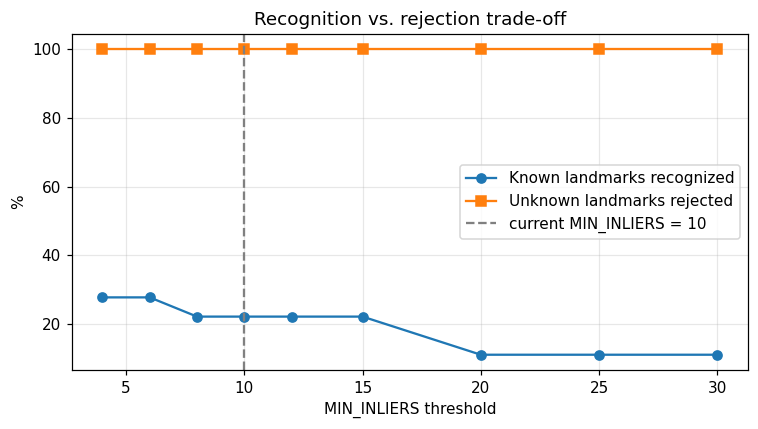

In [ ]:
sweep = []
for mi in [4, 6, 8, 10, 12, 15, 20, 25, 30]:
    dec = ev.apply(lambda r: decide(r.n_good, r.inliers, r.valid, min_inliers=mi), axis=1)
    final = np.where(dec, ev.top_candidate, "UNKNOWN")
    known_ok = ((final == ev.true) & (ev.true != "UNKNOWN")).sum() / max((ev.true != "UNKNOWN").sum(), 1)
    unk_ok = ((final == "UNKNOWN") & (ev.true == "UNKNOWN")).sum() / max((ev.true == "UNKNOWN").sum(), 1)
    sweep.append({"MIN_INLIERS": mi, "Known recognized (%)": round(100 * known_ok, 1),
                  "Unknown rejected (%)": round(100 * unk_ok, 1)})
sweep = pd.DataFrame(sweep)
display(sweep)

plt.figure(figsize=(7, 4))
plt.plot(sweep.MIN_INLIERS, sweep["Known recognized (%)"], "o-", label="Known landmarks recognized")
plt.plot(sweep.MIN_INLIERS, sweep["Unknown rejected (%)"], "s-", label="Unknown landmarks rejected")
plt.axvline(MIN_INLIERS, color="gray", ls="--", label=f"current MIN_INLIERS = {MIN_INLIERS}")
plt.xlabel("MIN_INLIERS threshold"); plt.ylabel("%"); plt.grid(alpha=.3); plt.legend()
plt.title("Recognition vs. rejection trade-off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/task6_threshold_sweep.png", bbox_inches="tight")
plt.show()

## Discussion of Performance and Limitations
*(Fill in the numbers from your own run, then keep, edit or delete the points below based on what you actually observed.)*

**Performance.** On the held-out queries the system recognized ___ % of known landmarks and rejected ___ % of unknown landmarks (Section 6.2), with a mean processing time of ___ s per query. In the six-condition test (Section 6.1), the original, resized and brightness-reduced images produced ___ reliable matches / ___ inliers, which is the expected behaviour because SIFT is scale- and rotation-invariant by construction and its gradient-based descriptors are normalised against illumination changes. The rotated image (45°) ___ .

**Why unknown images are rejected.** Any query has a top-ranked landmark, so a raw "largest match count" rule would always return a name. The combination of a minimum match count, RANSAC inliers that must agree on one geometric transformation, a minimum inlier ratio and a polygon-validity check rejects random matches that do not form a consistent structure.

**Limitations.**
1. **Viewpoint change.** SIFT is only *partly* invariant to 3D viewpoint change. Large angle differences, and the interior/exterior of the same building, produce few matches.
2. **Planar assumption.** A homography models a flat surface. Landmarks are 3D, so the projected polygon is an approximation and can be inaccurate for strongly oblique views.
3. **Repetitive structures** (arches of the Colosseum, bricks of the Great Wall, similar pyramids) generate ambiguous descriptors that the ratio test removes, which also lowers the match count for true positives.
4. **Low texture / blur / low resolution** (sky, water, small thumbnails, heavy darkening) gives few keypoints. The dataset images are web photos of varying quality.
5. **Occlusion and clutter** (crowds, scaffolding, vegetation) add non-landmark keypoints and shrink the inlier ratio.
6. **Scalability.** Brute-force matching against every reference image grows linearly with database size. For a real tourism system, use FLANN / approximate nearest neighbours, a Bag-of-Visual-Words or VLAD index, or a learned global descriptor for the first-stage retrieval, and keep SIFT + RANSAC only for verification.
7. **Threshold dependence.** `MIN_GOOD`, `MIN_INLIERS` and `MIN_INLIER_RATIO` were tuned on a small test set (Section 6.3). They should be re-tuned for a different database or image quality.

**Possible improvements.** More reference views per landmark (day/night, seasons), `RootSIFT` normalisation, cross-checking matches in both directions, `cv2.USAC_MAGSAC` for the homography, and combining SIFT with a CNN feature for robustness to extreme viewpoint changes.

## Package the deliverables
Creates `landmark_submission.zip` containing the organised database, query images, stored SIFT descriptors, result tables and all screenshots saved in `outputs/`. Add this notebook (`File → Download .ipynb`) to your submission as the source code.

In [ ]:
zip_path = f"{WORK_DIR}/landmark_submission.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (DB_DIR, QUERY_DIR, FEAT_DIR, OUT_DIR):
        for root, _, files_ in os.walk(folder):
            for f in files_:
                full = os.path.join(root, f)
                z.write(full, os.path.relpath(full, WORK_DIR))
print("Created", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

Created /content/landmark_submission.zip (22.2 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>